# Анализ и прогнозирование потребления домашних хозяйств в регионах России

Данные Росстата: фактическое конечное потребление домашних хозяйств на душу населения по субъектам РФ за 2000-2023 годы в текущих ценах, рублей. В работе регионы делятся на группы по характеру динамики, из трёх групп берётся по представителю, для них строятся и сравниваются прогнозы Holt, ARIMA и наивной модели, разбираются ошибки и даются рекомендации.

## Этап 1. Загрузка и подготовка данных

Файл «чистится» вручную: последняя колонка пустая из-за лишней запятой в каждой строке, годы записаны текстом с десятичной запятой, пропуски пустые или «…», а в названии Калининградской области стоит латинская p, и без замены регион не нашёлся бы по названию. Агрегаты отсекаются раньше, чем ряды проверяются на полноту. Одногодичный выброс ищется правилом «рост больше чем в 1.5 раза, а на следующий год падение ниже 0.8»: в текущих ценах потребление на душу почти всегда растёт, и вырасти втрое, чтобы тут же вернуться на прежнюю траекторию, реальный показатель не может, поэтому такая точка считается ошибкой ввода и заменяется средним соседних лет, а раз обе соседние точки фактические, длинный начальный фрагмент здесь не восстанавливается. Длинный формат с одной строкой на пару регион-год удобно фильтровать и группировать, годовой PeriodIndex понимают statsmodels и sktime, а светлый стиль графиков оставляет главными данные.

In [1]:
import itertools
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error, silhouette_score
from sklearn.preprocessing import StandardScaler
from sktime.forecasting.naive import NaiveForecaster
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.stattools import adfuller

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e',
    'axes.titlecolor': '#0b0b0b',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e8e7e2',
    'grid.linewidth': 0.6,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'legend.frameon': False,
    'lines.linewidth': 2,
    'axes.axisbelow': True,
})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
INK = '#0b0b0b'
MUTED = '#8a8981'

Path('figures').mkdir(exist_ok=True)
Path('tables').mkdir(exist_ok=True)

raw = pd.read_csv('data/rsdocs_1491005410458_wide_appendix_2025.csv')

In [2]:
raw = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')])
raw['region_name'] = raw['region_name'].str.strip()
raw['region_name'] = raw['region_name'].str.replace('Калинингpадская', 'Калининградская')
year_cols = [c for c in raw.columns if c.isdigit()]

values = (raw[year_cols].astype('string').apply(lambda s: s.str.strip())
          .replace({'…': pd.NA, '': pd.NA})
          .apply(lambda s: s.str.replace(',', '.', regex=False))
          .astype(float))
values.index = raw['region_name']

missing = values.isna().sum(axis=1)
missing_table = missing[missing > 0].rename('лет без данных').to_frame()
print('Территорий с пропусками:', len(missing_table))
print(missing_table)

Территорий с пропусками: 8
                                              лет без данных
region_name                                                 
Ненецкий автономный округ                                  3
Архангельская область без автономного округа              11
Республика Крым                                           14
г. Севастополь                                            14
Чеченская Республика                                       5
Ханты-Мансийский автономный округ – Югра                   3
Ямало-Ненецкий автономный округ                            3
Тюменская область без автономных округов                  11


In [3]:
def exclusion_reason(name, n_missing):
    if 'Российской Федерации' in name:
        return 'РФ в целом'
    if 'федеральный округ' in name:
        return 'федеральный округ'
    if 'без автономн' in name:
        return 'дублирующая запись'
    if n_missing > 0:
        return f'неполный ряд, нет {n_missing} лет'
    return None

reasons = pd.Series({name: exclusion_reason(name, n) for name, n in missing.items()})
excluded = reasons.dropna().rename('причина').rename_axis('территория').reset_index()
excluded.to_csv('tables/excluded.csv', index=False)
print(excluded.to_string(index=False))
print()
print('Исключено территорий:', len(excluded))

                                                                                             территория                  причина
Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего               РФ в целом
                                                                          Центральный федеральный округ        федеральный округ
                                                                      Северо-Западный федеральный округ        федеральный округ
                                                                              Ненецкий автономный округ  неполный ряд, нет 3 лет
                                                           Архангельская область без автономного округа       дублирующая запись
                                                                                Южный федеральный округ        федеральный округ
                                                                                        Республик

In [4]:
subjects = values.loc[reasons.isna()].copy()

ratio = subjects / subjects.shift(1, axis=1)
spike = (ratio > 1.5) & (ratio.shift(-1, axis=1) < 0.8)
outliers = [(r, y) for r, y in spike.stack().index[spike.stack()]]
print('Найдено одногодичных выбросов:', len(outliers))
for r, y in outliers:
    i = year_cols.index(y)
    prev_y, next_y = year_cols[i - 1], year_cols[i + 1]
    before = subjects.loc[r, y]
    subjects.loc[r, y] = (subjects.loc[r, prev_y] + subjects.loc[r, next_y]) / 2
    print(f'{r}, {y}: {prev_y} = {subjects.loc[r, prev_y]:,.1f}, {y} = {before:,.1f}, {next_y} = {subjects.loc[r, next_y]:,.1f}')
    print(f'  рост в {before / subjects.loc[r, prev_y]:.2f} раза, затем {subjects.loc[r, next_y] / before:.2f} от достигнутого')
    print(f'  значение {y}: до замены {before:,.1f}, после замены {subjects.loc[r, y]:,.1f}')

Найдено одногодичных выбросов: 1
Красноярский край, 2004: 2003 = 54,406.4, 2004 = 167,593.2, 2005 = 78,279.6
  рост в 3.08 раза, затем 0.47 от достигнутого
  значение 2004: до замены 167,593.2, после замены 66,343.0


In [5]:
long_df = (subjects.rename_axis('region').reset_index()
           .melt(id_vars='region', var_name='year', value_name='consumption'))
long_df['year'] = long_df['year'].astype(int)
print('Строк в длинном формате:', len(long_df))
print('Субъектов:', long_df['region'].nunique(), '| годы:', long_df['year'].min(), '-', long_df['year'].max())

series = {
    region: grp.set_index(pd.PeriodIndex(grp['year'].astype(str), freq='Y'))['consumption'].sort_index()
    for region, grp in long_df.groupby('region')
}
print('Рядов:', len(series), '| пропусков в рядах:', sum(int(s.isna().sum()) for s in series.values()))

Строк в длинном формате: 1896
Субъектов: 79 | годы: 2000 - 2023
Рядов: 79 | пропусков в рядах: 0


**Вывод.** Пропуски есть у 8 территорий: у Крыма и Севастополя нет 14 лет, у двух записей «без автономных округов» 11 лет, у Чечни 5 лет, у Ненецкого, Ханты-Мансийского и Ямало-Ненецкого округов по 3 года. Всего исключено 17 территорий: РФ в целом, 8 федеральных округов, 2 дублирующие записи и 6 субъектов с неполным рядом. Правило «рост больше чем в 1.5 раза, затем падение ниже 0.8» нашло в 79 рядах одну точку: Красноярский край, 2004 год, 167 593.2 рубля при 54 406.4 в 2003 и 78 279.6 в 2005 (рост в 3.08 раза и сразу 0.47 от достигнутого). Потребление на душу в текущих ценах не может вырасти втрое и через год вернуться на прежнюю траекторию, поэтому это ошибка в данных; точка заменена средним соседних лет, 66 343.0. Запрет задания касается длинных начальных фрагментов, а здесь восстановлена одна точка внутри ряда между двумя фактическими значениями. Остались 79 субъектов с полными рядами за 2000-2023 годы, в длинной таблице 1896 строк и ни одного пропуска. Архангельская и Тюменская области с округами оставлены: их автономные округа исключены, поэтому двойного счёта нет.

## Этап 2. Кластерный анализ регионов

Все пять признаков относительные: в текущих ценах абсолютный уровень отражает масштаб региона и инфляцию, поэтому уровень потребления нужен только для описания кластеров. K-means выбран потому, что признаков мало, все они числовые, а центры кластеров легко описать; признаки в разных единицах стандартизуются, иначе K-means смотрел бы в основном на отношение 2023/2000. Нужны три региона из разных кластеров, поэтому k выбирается между 3 и 4: сначала в каждом кластере должно быть не меньше трёх регионов, потом берётся больший силуэт. Кластеры пронумерованы по росту CAGR, чтобы их было проще читать, а медианные траектории показаны в долях от 2000 года, чтобы было видно, чем отличается динамика, а не уровень.

In [6]:
def features(s):
    growth = s.pct_change().dropna()
    return pd.Series({
        'cv': s.std() / s.mean(),
        'cagr': (s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1,
        'ratio_2023_2000': s.iloc[-1] / s.iloc[0],
        'max_drop': growth.min(),
        'share_down': (growth < 0).mean(),
    })

feat = pd.DataFrame({region: features(s) for region, s in series.items()}).T
print(feat.describe().loc[['mean', 'std', 'min', 'max']])

        cv  cagr  ratio_2023_2000  max_drop  share_down
mean 0.714 0.155           28.362     0.014       0.011
std  0.048 0.011            5.954     0.029       0.020
min  0.582 0.113           11.772    -0.094       0.000
max  0.819 0.187           51.310     0.067       0.087


In [7]:
scaler = StandardScaler()
X = scaler.fit_transform(feat)

models, sil = {}, {}
for k in (2, 3, 4):
    models[k] = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    sil[k] = silhouette_score(X, models[k].labels_)
    sizes = np.bincount(models[k].labels_)
    print(f'k={k}: silhouette={sil[k]:.3f}, размеры кластеров {sorted(sizes.tolist(), reverse=True)}')

sil_table = pd.DataFrame({'k': list(sil), 'silhouette': [round(v, 3) for v in sil.values()],
                          'min_size': [int(np.bincount(models[k].labels_).min()) for k in sil]})
sil_table.to_csv('tables/silhouette.csv', index=False)

k=2: silhouette=0.369, размеры кластеров [51, 28]


k=3: silhouette=0.409, размеры кластеров [46, 18, 15]
k=4: silhouette=0.375, размеры кластеров [34, 25, 14, 6]


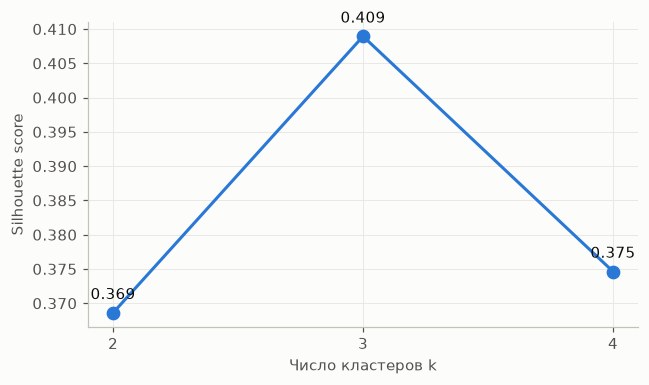

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(list(sil), list(sil.values()), color=SERIES[0], marker='o', markersize=8)
for k, v in sil.items():
    ax.annotate(f'{v:.3f}', (k, v), textcoords='offset points', xytext=(0, 9), ha='center', color=INK)
ax.set_xticks(list(sil))
ax.set_xlabel('Число кластеров k')
ax.set_ylabel('Silhouette score')
fig.tight_layout()
fig.savefig('figures/silhouette.png')
plt.show()

In [9]:
candidates = [k for k in (3, 4) if np.bincount(models[k].labels_).min() >= 3]
if not candidates:
    candidates = [3, 4]
k_best = max(candidates, key=lambda k: sil[k])
print('Подходят по размеру кластеров:', candidates, '| выбрано k =', k_best)

km = models[k_best]
order = np.argsort(np.argsort(scaler.inverse_transform(km.cluster_centers_)[:, 1]))
feat['cluster'] = order[km.labels_] + 1
centers = pd.DataFrame(km.cluster_centers_[np.argsort(order)], columns=feat.columns[:-1],
                       index=range(1, k_best + 1))

Подходят по размеру кластеров: [3, 4] | выбрано k = 3


In [10]:
level = pd.Series({region: s.mean() for region, s in series.items()})
level_2000 = pd.Series({region: s.iloc[0] for region, s in series.items()})
level_2023 = pd.Series({region: s.iloc[-1] for region, s in series.items()})
profile = feat.groupby('cluster').mean()
profile.insert(0, 'regions', feat.groupby('cluster').size())
profile['mean_level'] = level.groupby(feat['cluster']).mean()
profile['level_2000'] = level_2000.groupby(feat['cluster']).mean()
profile['level_2023'] = level_2023.groupby(feat['cluster']).mean()
profile = profile.round(3)
profile.rename_axis('cluster').reset_index().to_csv('tables/cluster_profile.csv', index=False)
print(profile.T)
print()
for c, grp in feat.groupby('cluster'):
    print(f'Кластер {c} ({len(grp)}):', ', '.join(sorted(grp.index)))

members = pd.DataFrame({'cluster': c, 'regions': len(grp), 'состав': ', '.join(sorted(grp.index))}
                        for c, grp in feat.groupby('cluster'))
members.to_csv('tables/cluster_members.csv', index=False)

cluster                   1           2           3
regions              18.000      15.000      46.000
cv                    0.660       0.697       0.740
cagr                  0.141       0.159       0.160
ratio_2023_2000      21.067      30.409      30.550
max_drop              0.004      -0.023       0.031
share_down            0.010       0.046       0.000
mean_level      240,781.067 203,429.355 200,042.797
level_2000       29,350.056  17,163.607  17,121.243
level_2023      574,476.883 502,100.627 519,919.491

Кластер 1 (18): Астраханская область, Вологодская область, Иркутская область, Камчатский край, Карачаево-Черкесская Республика, Красноярский край, Мурманская область, Новгородская область, Новосибирская область, Пермский край, Республика Башкортостан, Республика Коми, Республика Саха (Якутия), Самарская область, Смоленская область, Томская область, Тюменская область, г. Москва
Кластер 2 (15): Алтайский край, Воронежская область, Забайкальский край, Кемеровская область, Курга

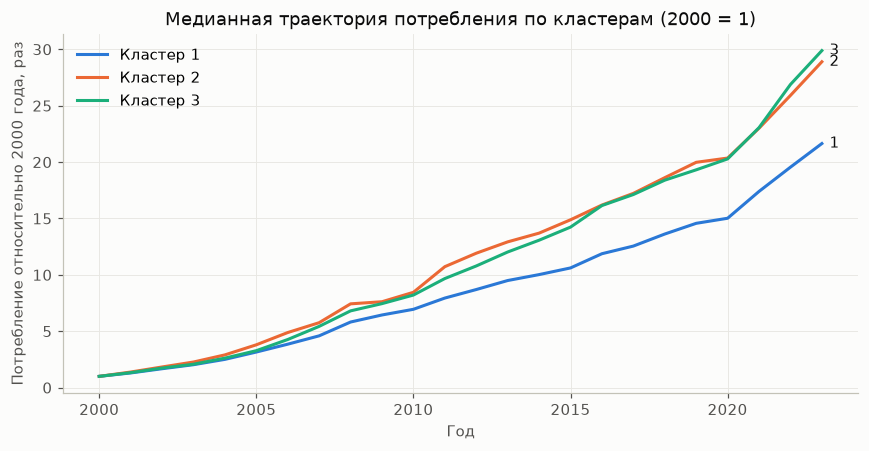

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
years = list(range(2000, 2024))
for c in sorted(feat['cluster'].unique()):
    idx = pd.DataFrame({r: series[r].values / series[r].iloc[0] for r in feat.index[feat['cluster'] == c]})
    med = idx.median(axis=1)
    ax.plot(years, med, color=SERIES[c - 1], label=f'Кластер {c}')
    ax.annotate(f'{c}', (years[-1], med.iloc[-1]), xytext=(5, 0), textcoords='offset points',
                va='center', color=INK)
ax.set_title('Медианная траектория потребления по кластерам (2000 = 1)')
ax.set_xlabel('Год')
ax.set_ylabel('Потребление относительно 2000 года, раз')
ax.legend()
fig.tight_layout()
fig.savefig('figures/cluster_trajectories.png')
plt.show()

**Вывод.** Силуэт: 0.369 при k=2, 0.409 при k=3 и 0.375 при k=4. При k=3 и k=4 в каждом кластере не меньше 3 регионов, и взято k=3 с наибольшим силуэтом: три группы различаются темпом роста и наличием лет снижения, а при k=4 появляется кластер из 6 регионов. Кластер 1 (18 регионов: Москва, Тюменская область, Коми, Якутия, Красноярский край и другие) стартовал с самого высокого уровня, в среднем 29 350 рублей в 2000 году против 17 164 и 17 121 у кластеров 2 и 3, и растёт медленнее всех, в 21.1 раза при CAGR 14.1%, а средний уровень у него самый высокий, 240 781 рубль. Кластер 2 (15 регионов: Ростовская, Свердловская, Челябинская, Кемеровская области и другие) вырос в 30.4 раза при CAGR 15.9%, но в среднем 4.6% лет у него со снижением, максимальное падение в среднем 2.3%. Кластер 3 (46 регионов) растёт так же быстро, как кластер 2, в 30.6 раза при CAGR 16.0%, но без лет снижения, а средний уровень у него самый низкий, 200 043 рубля.

## Этап 3. Выбор регионов для детального прогнозирования

Представителем кластера берётся регион, ближайший к центру в стандартизованном пространстве. Если кластеров четыре, берутся три с наибольшим суммарным расстоянием между центрами.

In [12]:
if k_best > 3:
    combos = itertools.combinations(centers.index, 3)
    chosen_clusters = max(combos, key=lambda cs: sum(np.linalg.norm(centers.loc[a] - centers.loc[b])
                                                      for a, b in itertools.combinations(cs, 2)))
else:
    chosen_clusters = tuple(centers.index)

Xdf = pd.DataFrame(X, index=feat.index, columns=feat.columns[:-1])
dist = pd.Series({r: np.linalg.norm(Xdf.loc[r] - centers.loc[feat.loc[r, 'cluster']]) for r in feat.index})
selected = [dist[feat['cluster'] == c].idxmin() for c in chosen_clusters]

sel_table = feat.loc[selected].copy()
sel_table['dist_to_center'] = dist[selected]
sel_table['rank_in_cluster'] = [int((dist[feat['cluster'] == feat.loc[r, 'cluster']] <= dist[r]).sum()) for r in selected]
sel_table = sel_table.round(3)
sel_table.rename_axis('region').reset_index().to_csv('tables/selected_regions.csv', index=False)
print(sel_table.T)
print()
print('Среднее расстояние до центра по кластерам:')
print(dist.groupby(feat['cluster']).mean().round(3))

                 Красноярский край  Ростовская область  Курская область
cv                           0.658               0.714            0.737
cagr                         0.138               0.158            0.160
ratio_2023_2000             19.582              29.447           30.467
max_drop                     0.005              -0.020            0.031
share_down                   0.000               0.043            0.000
cluster                      1.000               2.000            3.000
dist_to_center               0.607               0.427            0.078
rank_in_cluster              1.000               1.000            1.000

Среднее расстояние до центра по кластерам:
cluster
1   1.547
2   1.552
3   1.095
dtype: float64


**Вывод.** Из каждого из трёх кластеров взят регион, ближайший к центру. Красноярский край в кластере 1: расстояние 0.607 при среднем 1.547, рост в 19.6 раза, CAGR 13.8%, ни одного года снижения. Ростовская область в кластере 2: расстояние 0.427 при среднем 1.552, рост в 29.4 раза, CAGR 15.8%, одно снижение на 2.0%. Курская область в кластере 3: расстояние 0.078 при среднем 1.095, рост в 30.5 раза, CAGR 16.0%, минимальный годовой прирост 3.1%.

## Этап 4. Анализ выбранных регионов

Стационарность рядов описывается тестом Дики-Фуллера на уровнях, первых и вторых разностях полного ряда 2000-2023 годов. Названия регионов на графике сокращены, чтобы легенда не перекрывала линии.

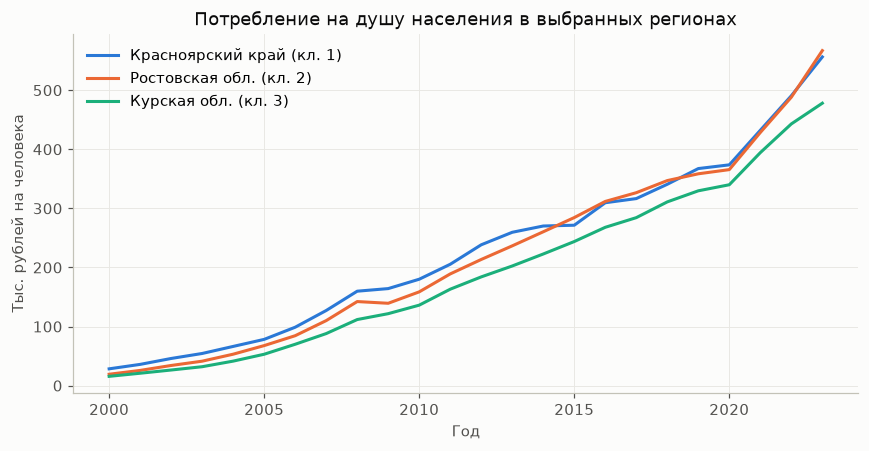

In [13]:
short = {r: r.replace('Республика', 'Респ.').replace('область', 'обл.') for r in selected}

fig, ax = plt.subplots(figsize=(8, 4.2))
for i, r in enumerate(selected):
    s = series[r]
    ax.plot(s.index.year, s.values / 1000, color=SERIES[i], label=f'{short[r]} (кл. {feat.loc[r, "cluster"]})')
ax.set_title('Потребление на душу населения в выбранных регионах')
ax.set_xlabel('Год')
ax.set_ylabel('Тыс. рублей на человека')
ax.legend()
fig.tight_layout()
fig.savefig('figures/selected_series.png')
plt.show()

In [14]:
adf_rows = []
for r in selected:
    s = series[r]
    for d_try, x in enumerate([s, s.diff().dropna(), s.diff().diff().dropna()]):
        stat, pvalue, *_ = adfuller(x, autolag='AIC', result_object=False)
        adf_rows.append({'region': r, 'series': ['уровни', '1-я разность', '2-я разность'][d_try],
                         'adf_stat': round(stat, 3), 'p_value': round(pvalue, 3)})
adf_table = pd.DataFrame(adf_rows)
adf_table.to_csv('tables/adf.csv', index=False)
print(adf_table.to_string(index=False))

            region       series  adf_stat  p_value
 Красноярский край       уровни     3.704    1.000
 Красноярский край 1-я разность    -0.107    0.949
 Красноярский край 2-я разность    -0.055    0.954
Ростовская область       уровни     1.963    0.999
Ростовская область 1-я разность    -1.182    0.681
Ростовская область 2-я разность    -5.693    0.000
   Курская область       уровни     4.627    1.000
   Курская область 1-я разность    -0.775    0.826
   Курская область 2-я разность    -0.339    0.920


Данные годовые, одна точка на год, поэтому внутригодовой сезонности в ряду нет и сезонная декомпозиция здесь не применяется.

**Вывод.** На уровнях p-value теста Дики-Фуллера не ниже 0.999: гипотеза о единичном корне не отвергается, ряды нестационарны и содержат тренд. У Красноярского края на полном ряду нестационарны первая и вторая разности (p=0.949 и 0.954), на train вторая разность тоже нестационарна (p=0.826). У Ростовской области первая разность нестационарна (p=0.681), а вторая стационарна (p=0.000), как и на train. У Курской области на полном ряду нестационарны обе разности (p=0.826 и 0.920), хотя на train первая разность стационарна (p=0.037): в полный ряд входит ускорение роста 2021-2023 годов, которое видно на графике, а в train его нет. Поэтому порядок d для ARIMA подбирается на этапе 5 тем же тестом, но только на train.

## Этап 5. Прогнозирование

Ряд делится на train 2000-2018 (19 лет, 79%) и test 2019-2023, горизонт 5 лет одинаков для всех регионов. Порядок d для ARIMA равен числу разностей до первого p < 0.05 в тесте Дики-Фуллера на train, чтобы тестовые годы не влияли на модель, и выше 2 на коротком годовом ряду не берётся; предупреждения отключены, потому что ARIMA на коротких рядах часто ругается на сходимость при переборе, а на выбор по AIC это не влияет. Лучшая модель региона выбирается по RMSE на test и для прогноза на 2024-2028 переобучается на всём ряду, чтобы учесть 2019-2023 годы, а на графике прогноз начинается от последней фактической точки, чтобы линия не обрывалась. ARIMA(0,2,0) продолжает последний годовой прирост, поэтому для неё печатается прирост 2023 года, а порядок ARIMA, выбранный по AIC на всём ряду, попадает в подпись графика ошибок.

In [15]:
TRAIN_END = pd.Period('2018', freq='Y')
H = 5
future_index = pd.period_range('2024', periods=H, freq='Y')

warnings.filterwarnings('ignore')

def fit_arima(y, d):
    trend = {0: 'c', 1: 't', 2: 'n'}[d]
    best = None
    for p, q in itertools.product(range(3), range(3)):
        try:
            res = ARIMA(y, order=(p, d, q), trend=trend).fit()
        except Exception:
            continue
        if best is None or res.aic < best[1].aic:
            best = ((p, d, q), res)
    return best

def forecast(model, y, h, d):
    if model == 'Holt':
        res = Holt(y, initialization_method='estimated').fit()
        return res.forecast(h), None
    if model == 'ARIMA':
        order, res = fit_arima(y, d)
        return res.forecast(h), order
    naive = NaiveForecaster(strategy='last').fit(y)
    pred = naive.predict(fh=list(range(1, h + 1)))
    return pred, None

In [16]:
adf_train_rows, d_order = [], {}
for r in selected:
    s = series[r][:TRAIN_END]
    pvals = []
    for d_try, x in enumerate([s, s.diff().dropna(), s.diff().diff().dropna()]):
        stat, pvalue, *_ = adfuller(x, autolag='AIC', result_object=False)
        pvals.append(pvalue)
        adf_train_rows.append({'region': r, 'series': ['уровни', '1-я разность', '2-я разность'][d_try],
                               'adf_stat': round(stat, 3), 'p_value': round(pvalue, 3)})
    d_order[r] = next((i for i, v in enumerate(pvals) if v < 0.05), 2)
adf_train = pd.DataFrame(adf_train_rows)
adf_train.to_csv('tables/adf_train.csv', index=False)
print(adf_train.to_string(index=False))
print()
print('Порядок d по train:', d_order)

            region       series  adf_stat  p_value
 Красноярский край       уровни    -2.329    0.163
 Красноярский край 1-я разность    -1.265    0.645
 Красноярский край 2-я разность    -0.778    0.826
Ростовская область       уровни     1.947    0.999
Ростовская область 1-я разность    -0.698    0.847
Ростовская область 2-я разность    -2.884    0.047
   Курская область       уровни     1.132    0.995
   Курская область 1-я разность    -2.973    0.037
   Курская область 2-я разность    -2.500    0.115

Порядок d по train: {'Красноярский край': 2, 'Ростовская область': 2, 'Курская область': 1}


In [17]:
MODELS = ['Naive', 'Holt', 'ARIMA']
test_pred, metrics, arima_orders = {}, [], {}
for r in selected:
    y = series[r]
    train, test = y[:TRAIN_END], y[TRAIN_END + 1:]
    for m in MODELS:
        pred, order = forecast(m, train, len(test), d_order[r])
        pred.index = test.index
        test_pred[(r, m)] = pred
        if order:
            arima_orders[r] = order
        metrics.append({'region': r, 'model': m,
                        'RMSE': root_mean_squared_error(test, pred),
                        'MAPE, %': 100 * mean_absolute_percentage_error(test, pred)})

metrics = pd.DataFrame(metrics).round(1)
metrics.to_csv('tables/metrics.csv', index=False)
print('Порядки ARIMA по AIC на train:', arima_orders)
print(metrics.pivot(index='model', columns='region', values=['RMSE', 'MAPE, %']).T)

best_model = metrics.loc[metrics.groupby('region')['RMSE'].idxmin()].set_index('region')['model'].to_dict()
print()
print('Лучшая модель:', best_model)

Порядки ARIMA по AIC на train: {'Красноярский край': (0, 2, 1), 'Ростовская область': (0, 2, 1), 'Курская область': (1, 1, 0)}
model                           ARIMA       Holt       Naive
        region                                              
RMSE    Красноярский край  69,619.400 70,590.300 125,730.900
        Курская область    42,353.200 31,390.800 103,408.400
        Ростовская область 58,641.600 66,015.900 122,815.800
MAPE, % Красноярский край      10.200     10.400      21.300
        Курская область         7.600      6.000      20.000
        Ростовская область      9.000      9.900      19.000

Лучшая модель: {'Красноярский край': 'ARIMA', 'Курская область': 'Holt', 'Ростовская область': 'ARIMA'}


In [18]:
future, full_label = {}, {}
for r in selected:
    pred, order = forecast(best_model[r], series[r], H, d_order[r])
    pred.index = future_index
    future[r] = pred
    full_label[r] = f'ARIMA{order}' if order else best_model[r]
    if order:
        print(r, 'ARIMA на всём ряду:', order)
    if order == (0, 2, 0):
        print(r, 'прирост 2023 года, тыс. рублей:', round(series[r].diff().iloc[-1] / 1000, 1))

future_table = pd.DataFrame(future).round(0)
future_table.index = future_table.index.year
last = pd.Series({r: series[r].iloc[-1] for r in selected})
summary = pd.DataFrame({
    'model': [best_model[r] for r in selected],
    'value_2023': last.values.round(0),
    'value_2028': future_table.loc[2028].values,
    'growth_2028_vs_2023_%': (100 * (future_table.loc[2028] / last - 1)).values.round(1),
    'avg_growth_%': (100 * ((future_table.loc[2028] / last) ** (1 / H) - 1)).values.round(1),
}, index=selected)
future_table.rename_axis('year').reset_index().to_csv('tables/forecast_2024_2028.csv', index=False)
summary.rename_axis('region').reset_index().to_csv('tables/forecast_summary.csv', index=False)
print(future_table)
print()
print(summary.T)

Красноярский край ARIMA на всём ряду: (0, 2, 1)


Ростовская область ARIMA на всём ряду: (0, 2, 0)
Ростовская область прирост 2023 года, тыс. рублей: 78.8
      Красноярский край  Ростовская область  Курская область
2024        612,344.000         645,859.000      515,266.000
2025        668,349.000         724,687.000      552,507.000
2026        724,355.000         803,514.000      589,748.000
2027        780,360.000         882,342.000      626,988.000
2028        836,366.000         961,169.000      664,229.000

                      Красноярский край Ростовская область Курская область
model                             ARIMA              ARIMA            Holt
value_2023                  556,338.000        567,032.000     478,026.000
value_2028                  836,366.000        961,169.000     664,229.000
growth_2028_vs_2023_%            50.300             69.500          39.000
avg_growth_%                      8.500             11.100           6.800


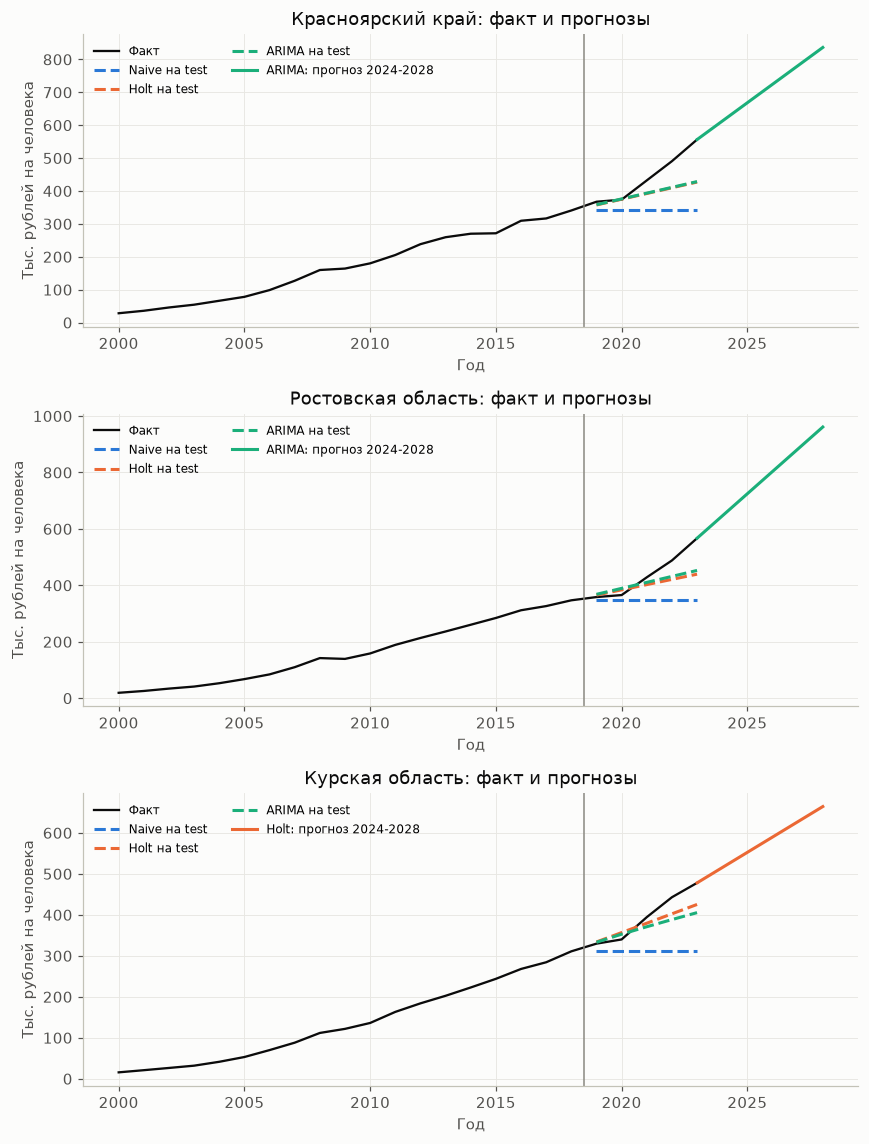

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10.5))
for ax, r in zip(axes, selected):
    y = series[r]
    ax.plot(y.index.year, y.values / 1000, color=INK, linewidth=1.5, label='Факт')
    for i, m in enumerate(MODELS):
        p = test_pred[(r, m)]
        ax.plot(p.index.year, p.values / 1000, color=SERIES[i], linestyle='--', label=f'{m} на test')
    f = pd.concat([y.iloc[-1:], future[r]])
    ax.plot(f.index.year, f.values / 1000, color=SERIES[MODELS.index(best_model[r])],
            label=f'{best_model[r]}: прогноз 2024-2028')
    ax.axvline(2018.5, color=MUTED, linewidth=1)
    ax.set_title(f'{r}: факт и прогнозы')
    ax.set_xlabel('Год')
    ax.set_ylabel('Тыс. рублей на человека')
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig('figures/forecasts.png')
plt.show()

**Вывод.** По тесту Дики-Фуллера на train у Курской области стационарна первая разность (p=0.037), d=1, у Ростовской области вторая (p=0.047), d=2. У Красноярского края p-value 0.826 и после вторых разностей. Взято d=2: на 19 годовых точках train разности выше второй не берутся, а мощность теста Дики-Фуллера на таком коротком ряду мала, и неотвергнутый единичный корень ещё не значит, что нужна третья разность.Для Красноярского края лучшая модель ARIMA(0,2,1) с RMSE 69 619.4 и MAPE 10.2%, для Ростовской области ARIMA(0,2,1) с RMSE 58 641.6 и MAPE 9.0%, для Курской области Holt с RMSE 31 390.8 и MAPE 6.0%, ARIMA(1,1,0) там хуже (42 353.2). Все модели занижают 2021-2023 годы: на графике факт уходит вверх от прогнозов, потому что модели продолжают линейный тренд train, а рост в эти годы ускорился. В Ростовской области ARIMA с d=2 даёт на test линию круче, чем у Holt, и поэтому меньше занижает 2021-2023 годы. Прогноз Ростовской области на 2024-2028 строит ARIMA(0,2,0), выбранная на всём ряду: она продолжает прирост 2023 года, +78.8 тыс. рублей в год. По лучшей модели к 2028 году потребление вырастет на 50.3% в Красноярском крае (до 836 366 рублей), на 69.5% в Ростовской области (до 961 169) и на 39.0% в Курской области (до 664 229).

## Этап 6. Анализ ошибок

Ошибки считаются как одношаговые прогнозы внутри выборки для лучшей модели, оценённой на всём ряду. Первые два года пропускаются: у модели там ещё нет истории, чтобы оценить тренд. Для гипотез об ошибках печатается годовой прирост регионов в годы, с которыми эти гипотезы связаны, а на диаграмме цветом выделены пять лет с наибольшей ошибкой, остальные годы серые.

In [20]:
def one_step(model, y, d):
    if model == 'Holt':
        return Holt(y, initialization_method='estimated').fit().fittedvalues
    if model == 'ARIMA':
        return fit_arima(y, d)[1].predict(start=y.index[0], end=y.index[-1])
    return y.shift(1)

err_rows = []
for r in selected:
    y = series[r]
    fitted = one_step(best_model[r], y, d_order[r])
    e = pd.DataFrame({'actual': y, 'predicted': fitted}).iloc[2:]
    e['error_%'] = 100 * (e['actual'] - e['predicted']) / e['actual']
    e['region'] = r
    err_rows.append(e)
errors = pd.concat(err_rows)
errors['year'] = errors.index.year

top5 = (errors.assign(abs_err=errors['error_%'].abs())
        .sort_values('abs_err', ascending=False))
top5 = (top5[top5.groupby('region').cumcount() < 5]
        .sort_values(['region', 'abs_err'], ascending=[True, False]))
top5 = top5[['region', 'year', 'actual', 'predicted', 'error_%']].round(1)
top5.to_csv('tables/top5_errors.csv', index=False)
print(top5.to_string(index=False))

growth = pd.DataFrame({r: 100 * series[r].pct_change() for r in selected})
growth.index = growth.index.year
growth_years = growth.loc[[2009, 2010, 2015, 2016, 2020, 2021]].round(1).T
growth_years.rename_axis('region').reset_index().to_csv('tables/growth_years.csv', index=False)
print()
print(growth_years)

            region  year      actual   predicted  error_%
 Красноярский край  2009 164,230.300 186,934.800  -13.800
 Красноярский край  2021 432,207.100 388,631.300   10.100
 Красноярский край  2007 127,141.300 114,669.100    9.800
 Красноярский край  2006  98,845.700  89,646.400    9.300
 Красноярский край  2016 309,547.200 281,163.700    9.200
   Курская область  2006  70,005.300  62,327.600   11.000
   Курская область  2021 394,356.600 356,607.300    9.600
   Курская область  2008 111,828.900 102,766.700    8.100
   Курская область  2002  26,421.600  28,510.800   -7.900
   Курская область  2004  41,463.600  38,241.900    7.800
Ростовская область  2009 139,375.100 174,505.100  -25.200
Ростовская область  2010 158,695.200 136,475.100   14.000
Ростовская область  2021 428,455.100 372,672.100   13.000
Ростовская область  2004  53,198.900  48,630.100    8.600
Ростовская область  2007 110,045.100 101,224.500    8.000

year                 2009   2010  2015   2016  2020   2021
Красноярский

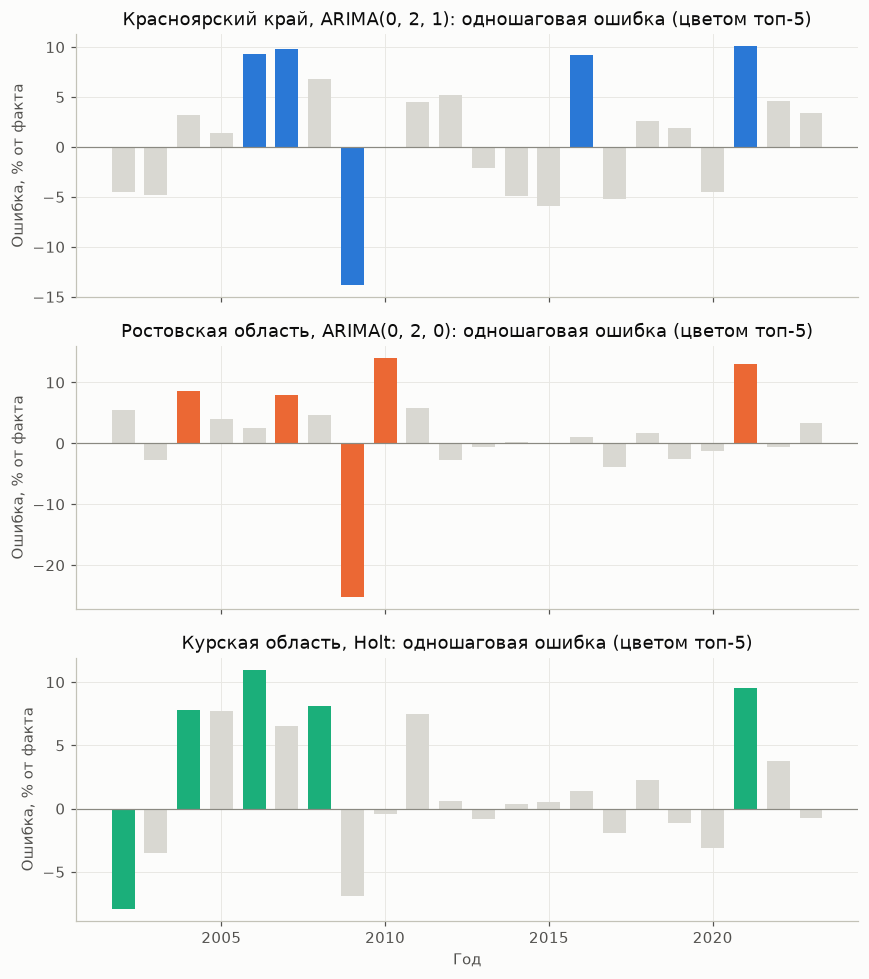

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
for i, (ax, r) in enumerate(zip(axes, selected)):
    e = errors[errors['region'] == r]
    top_years = set(top5.loc[top5['region'] == r, 'year'])
    colors = [SERIES[i] if y in top_years else '#d9d8d2' for y in e['year']]
    ax.bar(e['year'], e['error_%'], color=colors, width=0.7)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(f'{r}, {full_label[r]}: одношаговая ошибка (цветом топ-5)')
    ax.set_ylabel('Ошибка, % от факта')
axes[-1].set_xlabel('Год')
fig.tight_layout()
fig.savefig('figures/errors.png')
plt.show()

**Вывод.** Ошибки посчитаны для лучшей модели, оценённой на всём ряду; у Ростовской области это ARIMA(0,2,0). У Ростовской области наибольшая ошибка в 2009 году, -25.2%: модель ждала 174 505 рублей, а факт 139 375, потребление в тот год снизилось на 2.0%. У Красноярского края в 2009 году тоже переоценка (-13.8%): кризис 2008-2009 годов остановил рост доходов, а модели продолжили докризисный тренд; у Ростовской области следом идёт недооценка восстановления 2010 года (+14.0%). Во всех трёх регионах в топ-5 попал 2021 год (от +9.6% до +13.0%): в 2020 году рост замедлился (прирост 1.7-3.1%), а в 2021 году потребление выросло на 15.7-17.2% на фоне восстановления и ускорения инфляции. Недооценка 2006-2007 годов (у Курской области и 2008 года) связана с докризисным ростом доходов. У Красноярского края в топ попал и 2016 год (+9.2%): в 2015 году после падения цен на нефть и девальвации рост почти остановился (прирост 0.5%), а в 2016 году вернулся (14.0%). Ошибки 2002 и 2004 годов у Курской и Ростовской областей связаны с короткой историей: модели ещё не оценили тренд.

## Этап 7. Индивидуальные рекомендации

Цифры для рекомендаций берутся из прогноза лучшей модели на 2024-2028 годы и из уровня региона относительно среднего по субъектам.

In [22]:
avg_2023 = level_2023.mean()
reco = summary[['model', 'value_2023', 'value_2028', 'growth_2028_vs_2023_%', 'avg_growth_%']].copy()
reco['2023_vs_avg_%'] = (100 * (summary['value_2023'] / avg_2023 - 1)).round(1)
reco.rename_axis('region').reset_index().to_csv('tables/reco.csv', index=False)
print('Среднее по 79 субъектам в 2023 году:', round(avg_2023))
print(reco.T)

Среднее по 79 субъектам в 2023 году: 528967
                      Красноярский край Ростовская область Курская область
model                             ARIMA              ARIMA            Holt
value_2023                  556,338.000        567,032.000     478,026.000
value_2028                  836,366.000        961,169.000     664,229.000
growth_2028_vs_2023_%            50.300             69.500          39.000
avg_growth_%                      8.500             11.100           6.800
2023_vs_avg_%                     5.200              7.200          -9.600


**Рекомендации.**

Красноярский край (кластер 1, ARIMA):
- По прогнозу потребление на душу вырастет с 556 338 рублей в 2023 году до 836 366 рублей в 2028 году, на 50.3%, или 8.5% в год, а уровень 2023 года на 5.2% выше среднего по 79 субъектам. Под этот темп стоит планировать торговые площади и социальные расходы края.
- Доходы населения края во многом зависят от цветной металлургии, лесной и добывающей отрасли, поэтому бюджетные и социальные программы края стоит проверять, помимо продолжения тренда, на сценарий падения мировых цен на металлы.

Ростовская область (кластер 2, ARIMA):
- Прогноз даёт рост с 567 032 рублей в 2023 году до 961 169 рублей в 2028 году, на 69.5%, или 11.1% в год. Уровень 2023 года на 7.2% выше среднего по субъектам. Модель переносит на будущее ускорение 2021-2023 годов, поэтому планы области по потребительскому рынку стоит строить на этом прогнозе как на верхней границе и пересматривать по фактическим данным каждого года.
- В кризис 2009 года потребление в Ростовской области снизилось, поэтому для области с крупным аграрным и транспортным комплексом юга стоит заранее готовить меры поддержки доходов на случай нового спада.

Курская область (кластер 3, Holt):
- По Holt потребление вырастет с 478 026 рублей в 2023 году до 664 229 рублей в 2028 году, на 39.0%, или 6.8% в год. При этом в 2023 году область на 9.6% ниже среднего по субъектам, и программы поддержки доходов стоит нацелить на то, чтобы этот разрыв сокращался быстрее прогноза.
- Курская область аграрная и приграничная. Области стоит заранее зарезервировать маршруты и склады для снабжения приграничных районов и поддержать торговлю в этих районах, чтобы перебои с поставками не сокращали потребление.

**Вывод.** По прогнозу Красноярский край растёт на 8.5% в год, Ростовская область на 11.1%, Курская область на 6.8%. В 2023 году Красноярский край выше среднего по субъектам на 5.2%, Ростовская область на 7.2%, Курская область ниже на 9.6%. Рекомендации опираются на прогноз и положение каждого региона: для Красноярского края проверка на сырьевой шок, для Ростовской области прогноз как верхняя граница, для Курской области сокращение отставания от среднего уровня и резерв логистики приграничных районов.

## Этап 8. Выводы по проекту

По пяти относительным признакам динамики 79 субъектов разделились на 3 кластера (силуэт 0.409). Большой кластер 3 из 46 регионов вырос за 2000-2023 годы в 30.6 раза и ни разу не снижался. Кластер 2 из 15 регионов вырос так же, в 30.4 раза, но с отдельными годами снижения. Кластер 1 из 18 регионов, в том числе Москва и Тюменская область, стартовал с высокого уровня (в среднем 29 350 рублей в 2000 году) и вырос меньше, в 21.1 раза.

Для представителей кластера 1 (Красноярский край) и кластера 2 (Ростовская область) лучшей оказалась ARIMA(0,2,1), MAPE 10.2% и 9.0%. Для представителя кластера 3 (Курская область) лучше Holt с MAPE 6.0%, у ARIMA(1,1,0) 7.6%. Наивный прогноз проигрывает обеим моделям во всех регионах (MAPE 19.0-21.3%), так что тренд в рядах сильный и модели его улавливают. В одношаговых ошибках самые крупные промахи у Красноярского края и Ростовской области приходятся на кризис 2009 года (-13.8% и -25.2%), у Курской области на 2006 год (+11.0%).